# HYNET Task 3.2 reference test case — presentation

This notebook presents the `tx-full` variant of the common reference test case of HYNET
Task 3.2: the IEEE 39-bus and IEEE 14-bus systems joined by a VSC HVDC link, with four
bidding zones, three operating scenarios and two batteries for adequacy studies.

It reads only the published files in `testcase/`. The load flows below are run live with
pypowsybl (OpenLoadFlow) to illustrate the operating points; they are not results of any
HYNET tool.

Schemas and conventions are documented in [`docs/test-case.md`](../docs/test-case.md) and
[`docs/data-dictionary.md`](../docs/data-dictionary.md).

In [1]:
import logging

# pypowsybl logs a notice about optional dependencies when it is first imported.
logging.getLogger("powsybl").setLevel(logging.ERROR)

import pandas as pd
import pypowsybl as pp
from IPython.display import SVG, display

from hynet_testcase.network.loadflow import run_ac
from hynet_testcase.paths import RepoPaths
from hynet_testcase.scenarios.report import branch_loadings, bus_voltages
from hynet_testcase.viz.plots import (
    ZONE_COLORS, plot_dispatch, plot_loadings, plot_voltage_profiles, plot_zone_balance,
    zone_diagram_parameters, zone_diagram_profile,
)

TX_FULL = RepoPaths.discover().testcase / "tx-full"


def read_csv(path):
    # Most ids end with a space: read them as text, untouched.
    return pd.read_csv(TX_FULL / path, dtype={"generator_id": str, "load_id": str}, keep_default_na=False)

## 1. Network

In [2]:
network = pp.network.load(str(TX_FULL / "network/base/xiidm/tx-full_base.xiidm"))
bus_zones = read_csv("zones/bus_zones.csv")

voltage_levels = network.get_voltage_levels()
summary = pd.DataFrame({
    "buses": network.get_bus_breaker_view_buses()["voltage_level_id"].map(voltage_levels["nominal_v"]).value_counts(),
    "lines": network.get_lines()["voltage_level1_id"].map(voltage_levels["nominal_v"]).value_counts(),
    "transformers": network.get_2_windings_transformers()["voltage_level1_id"].map(voltage_levels["nominal_v"]).value_counts(),
    "generators": network.get_generators()["voltage_level_id"].map(voltage_levels["nominal_v"]).value_counts(),
    "loads": network.get_loads()["voltage_level_id"].map(voltage_levels["nominal_v"]).value_counts(),
}).fillna(0).astype(int).rename_axis("nominal voltage (kV)")
summary.index = summary.index.map({138.0: "138 kV (IEEE 14)", 345.0: "345 kV (IEEE 39)"})
summary

,buses,lines,transformers,generators,loads
nominal voltage (kV),,,,,
345 kV (IEEE 39),39,34,12,10,31
138 kV (IEEE 14),14,17,3,5,11


### Network-area diagram

Buses are coloured by bidding zone; branch labels are active power flows (MW) of the base
case. The grey element between zones Z1 and Z0 is the HVDC link.

■ Z0 · ■ Z1 · ■ Z2 · ■ Z3

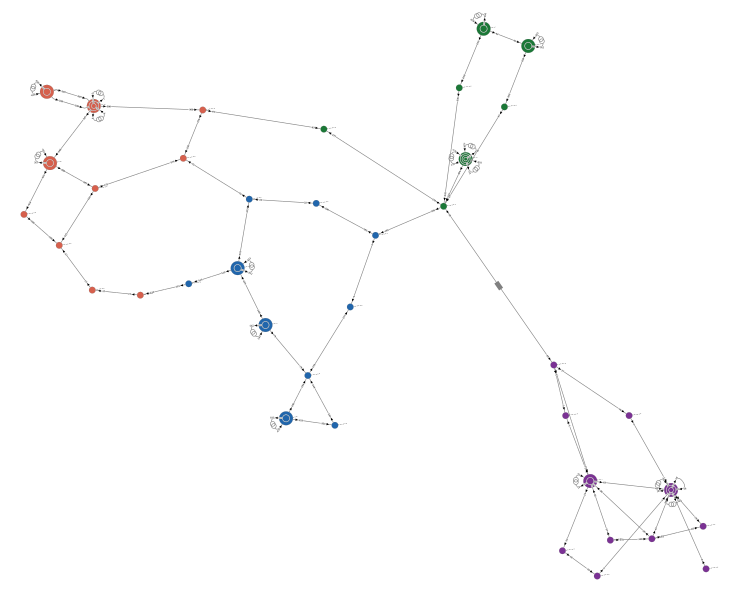

In [3]:
legend = " · ".join(f'<span style="color:{color}">■ {zone}</span>' for zone, color in ZONE_COLORS.items())
display({"text/html": legend}, raw=True)
display(SVG(network.get_network_area_diagram(
    nad_parameters=zone_diagram_parameters(),
    nad_profile=zone_diagram_profile(network, bus_zones)).svg))

### Interactive explorer

The explorer below needs a live kernel (for example on Binder); it is not rendered on
GitHub. It opens on bus 16, where the HVDC link leaves IEEE 39.

In [4]:
from pypowsybl_jupyter import network_explorer

network_explorer(network, vl_id="VL16", depth=2)

## 2. Bidding zones

IEEE 14 forms zone Z0; IEEE 39 is split into its three classic areas Z1–Z3.

In [5]:
element_zones = read_csv("zones/element_zones.csv")
generators = read_csv("scenarios/generators.csv")
capacity = (element_zones[element_zones["element_type"] == "generator"]
            .merge(generators, left_on="element_id", right_on="generator_id")
            .groupby("zone_id")["nominal_p_mw"].sum())
pd.DataFrame({
    "buses": bus_zones["zone_id"].value_counts(),
    "generators": element_zones[element_zones["element_type"] == "generator"]["zone_id"].value_counts(),
    "loads": element_zones[element_zones["element_type"] == "load"]["zone_id"].value_counts(),
    "installed capacity (MW)": capacity,
}).sort_index()

,buses,generators,loads,installed capacity (MW)
zone_id,,,,
Z0,14,5,11,515.0
Z1,12,4,8,3202.0
Z2,13,3,10,2305.0
Z3,14,3,13,3045.0


In [6]:
read_csv("zones/interconnections.csv")

,interconnection_id,type,zone_from,zone_to,capacity_mw
0,L-1-39-1,ac_branch,Z2,Z3,999.7
1,L-14-15-1,ac_branch,Z3,Z1,599.9
2,L-16-17-1,ac_branch,Z1,Z2,599.9
3,L-3-4-1,ac_branch,Z2,Z3,500.2
4,HVDC_Link_16_113,hvdc,Z1,Z0,60.0


## 3. HVDC link

In [7]:
hvdc = network.get_hvdc_lines()[["converter_station1_id", "converter_station2_id", "converters_mode", "max_p", "nominal_v", "r"]]
hvdc

,converter_station1_id,converter_station2_id,converters_mode,max_p,nominal_v,r
id,,,,,,
HVDC_Link_16_113,VSC_Station_16,VSC_Station_113,SIDE_1_RECTIFIER_SIDE_2_INVERTER,60.0,150.0,5.0


In [8]:
read_csv("scenarios/hvdc.csv")

,timestamp,scenario_id,scenario_name,hvdc_line_id,target_p_mw
0,2025-01-01T00:00:00Z,S1,baseline,HVDC_Link_16_113,50.0
1,2025-01-01T01:00:00Z,S2,high_res_low_demand,HVDC_Link_16_113,60.0
2,2025-01-01T02:00:00Z,S3,low_res_high_demand,HVDC_Link_16_113,50.0


## 4. Scenarios

| Id | Name | Loads | RES output | HVDC |
|----|------|-------|------------|------|
| S1 | `baseline` | × 1.00 | 50 % | 50 MW |
| S2 | `high_res_low_demand` | × 0.70 | 100 % | 60 MW (maximum) |
| S3 | `low_res_high_demand` | × 1.05 | 10 % | 50 MW |

Non-RES units are dispatched in merit order within each AC island.

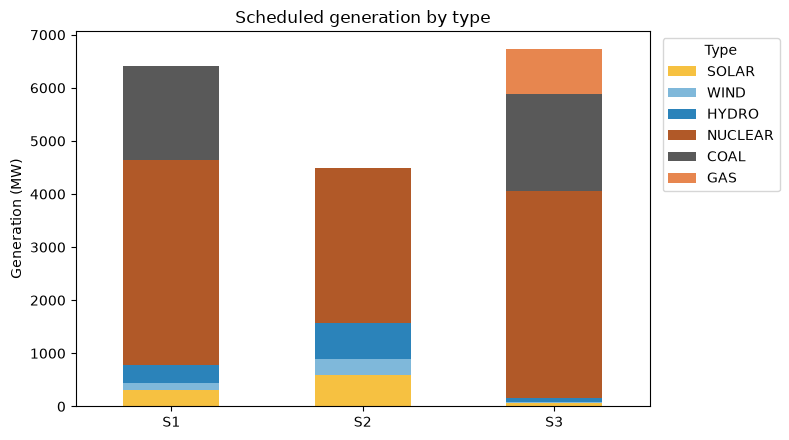

In [9]:
generation = read_csv("scenarios/generation.csv")
plot_dispatch(generation, generators);

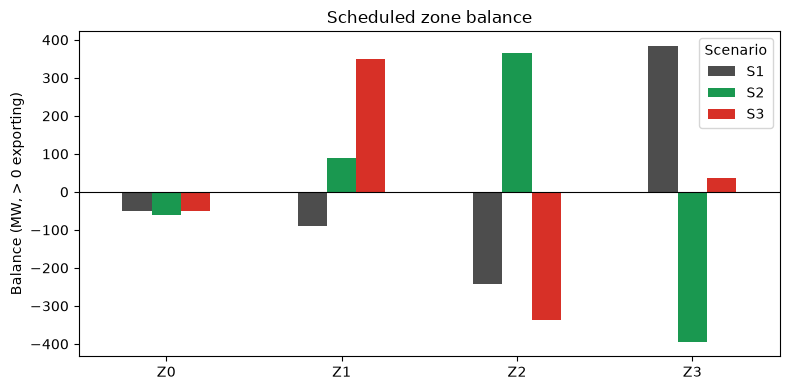

In [10]:
plot_zone_balance(read_csv("zones/zone_balance.csv"));

## 5. Operating points

Each scenario snapshot is loaded and solved with an AC load flow (distributed slack in
proportion to the dispatched units), as the build does.

In [11]:
voltages, loadings = {}, {}
for scenario in ("S1", "S2", "S3"):
    snapshot = pp.network.load(str(TX_FULL / f"scenarios/snapshots/{scenario}/xiidm/tx-full_base_{scenario}.xiidm"))
    run_ac(snapshot, scenario)
    voltages[scenario] = bus_voltages(snapshot)
    loadings[scenario] = branch_loadings(snapshot)

### Voltage profiles

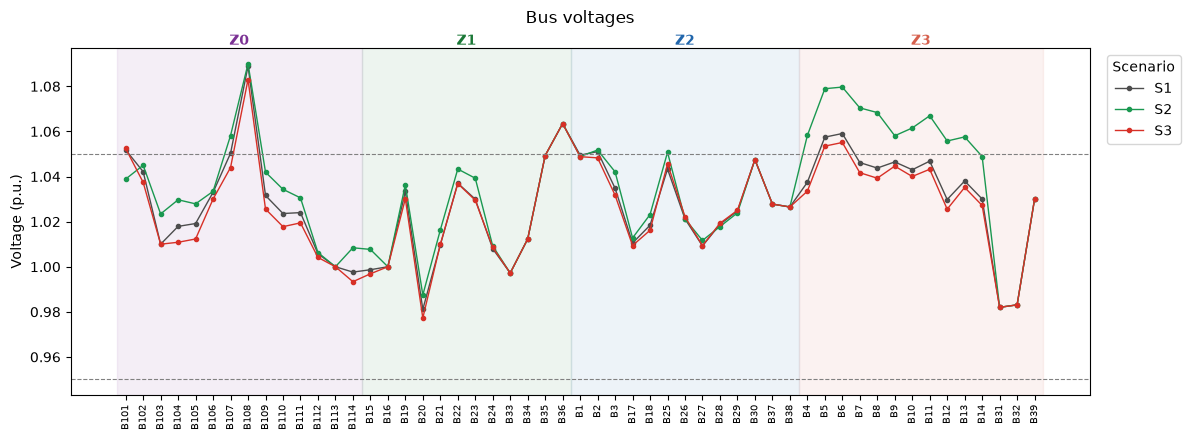

In [12]:
plot_voltage_profiles(voltages, bus_zones);

### Branch loadings

Every line and transformer has a permanent current limit; S3 is meant to stress them.

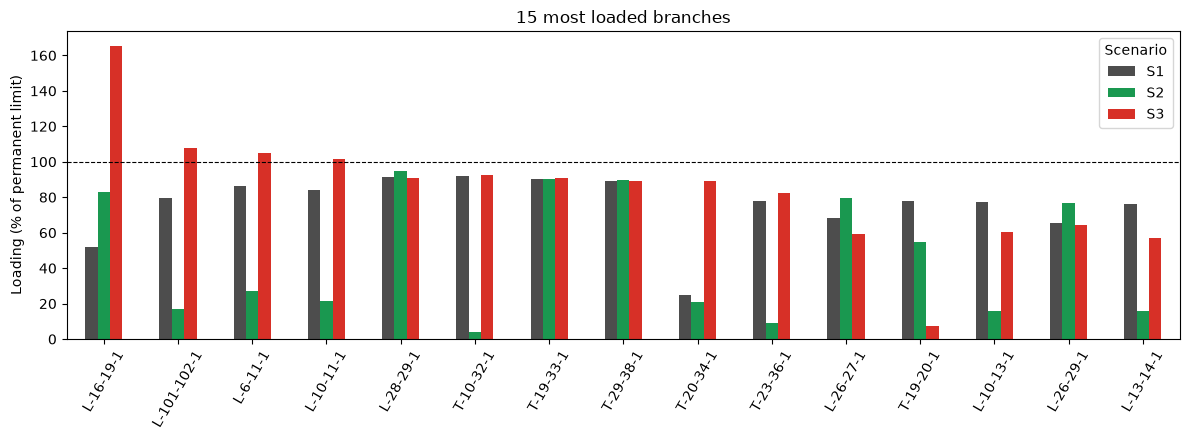

In [13]:
plot_loadings(loadings);

In [14]:
overloads = pd.DataFrame(loadings).rename_axis("branch")
overloads.index = overloads.index.str.strip()
overloads[(overloads > 100).any(axis=1)].round(0)

,S1,S2,S3
branch,,,
L-6-11-1,86.0,27.0,105.0
L-10-11-1,84.0,22.0,102.0
L-101-102-1,80.0,17.0,108.0
L-16-19-1,52.0,83.0,165.0


## 6. Batteries

Adequacy data only: the batteries are not part of the network models.

In [15]:
read_csv("storage/batteries.csv")

,battery_id,bus_id,zone_id,power_mw,energy_mwh,charge_efficiency,discharge_efficiency,initial_soc,final_soc
0,BAT-B106-1,B106,Z0,10.0,20.0,0.95,0.95,0.5,0.5
1,BAT-B6-1,B6,Z3,100.0,200.0,0.95,0.95,0.5,0.5


## Not yet included

Economic assumptions, contingency list, the `reinforced` network case, the reduced
variant `tx-reduced` and the distribution variant `dx-33` will be added in later versions.

---

<img src="../docs/assets/eu-emblem.svg" alt="Flag of the European Union" height="40">

HYNET project has received funding from the European Union's Horizon Europe research and
innovation programme under Grant Agreement No 101172757.